### Demo

In [1]:
import os
import numpy as np
import pandas as pd
import random
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms

import sklearn
import pickle

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
# device = "cpu"

In [3]:
random.seed(1234)
torch.manual_seed(1234)

#### Model Flag

In [4]:
# MODEL_FLAG = 'resnet'
# MODEL_FLAG = 'EfficientNet_V2'
# MODEL_FLAG = 'MobileNet_V3'
# MODEL_FLAG = 'SwinTransformer'
# MODEL_FLAG = 'ViT'
# MODEL_FLAG = 'ConvNeXt'
MODEL_FLAG = 'maxvit'

IS_FUSION = True

In [5]:
pretrain = True

#### Model Builder

In [6]:
if MODEL_FLAG == 'resnet':
    from torchvision.models import resnet18, ResNet18_Weights

    if pretrain:
        model = resnet18(weights="IMAGENET1K_V1")
    else:
        model = resnet18(weights=None)

elif MODEL_FLAG == 'SwinTransformer':
    from torchvision.models import swin_v2_t, Swin_V2_T_Weights

    if pretrain:
        model = swin_v2_t(weights="IMAGENET1K_V1")
    else:
        model = swin_v2_t(weights=None)

elif MODEL_FLAG == 'EfficientNet_V2':
    from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

    if pretrain:
        model = efficientnet_v2_s(weights="IMAGENET1K_V1")
    else:
        model = efficientnet_v2_s(weights=None)

elif MODEL_FLAG == 'MobileNet_V3':
    from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

    if pretrain:
        model = mobilenet_v3_small(weights="IMAGENET1K_V1")
    else:
        model = mobilenet_v3_small(weights=None)

elif MODEL_FLAG == 'ViT':
    from torchvision.models import vit_b_16, ViT_B_16_Weights

    if pretrain:
        model = vit_b_16(weights="IMAGENET1K_V1")
    else:
        model = vit_b_16(weights=None)

elif MODEL_FLAG == 'ConvNeXt':
    from torchvision.models import convnext_small, ConvNeXt_Small_Weights

    if pretrain:
        model = convnext_small(weights="IMAGENET1K_V1")
    else:
        model = convnext_small(weights=None)
        
elif MODEL_FLAG == 'maxvit':
    from torchvision.models import maxvit_t, MaxVit_T_Weights

    if pretrain:
        model = maxvit_t(weights="IMAGENET1K_V1")
    else:
        model = maxvit_t(weights=None)

/home/fangyijie/miniconda3/envs/sam_env/lib/python3.11/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /opt/conda/conda-bld/pytorch_1702400430266/work/aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [7]:
#add another fully connected layer to convert output (1,1000) to (1)
class GaResnetModel(nn.Module):
    def __init__(self, pretrain_model):
        super().__init__()
        self.pretrained_model = pretrain_model # delete the last fc layer.
        self.regression = nn.Linear(1000, 256)

    def forward(self, x):
        # input size of x (b, 3, 256, 256) where b is the batch size
        x = self.pretrained_model(x) #output size (b, 1000)
        x = nn.ReLU()(x)
        x = self.regression(x) #output size (1)

        return x

In [8]:
class FusionModel(nn.Module):
    def __init__(self, img_model, in_channel=256, num_classes=1):
        super().__init__()
        self.img_model = img_model
        self.MLP = nn.Sequential(
            # nn.Linear(in_channel, num_classes),
            # nn.ReLU(),
            nn.Linear(in_channel, num_classes)
        )

    def forward(self, x1, x2):
        o1 = self.img_model(x1)
        x = torch.cat((o1, x2), 1)
        out = self.MLP(x)

        return out

In [9]:
img_model = GaResnetModel(model)
model = FusionModel(img_model, in_channel=351) # 256+95

In [10]:
model

FusionModel(
  (img_model): GaResnetModel(
    (pretrained_model): MaxVit(
      (stem): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.99, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
      )
      (blocks): ModuleList(
        (0): MaxVitBlock(
          (layers): ModuleList(
            (0): MaxVitLayer(
              (layers): Sequential(
                (MBconv): MBConv(
                  (proj): Sequential(
                    (0): AvgPool2d(kernel_size=3, stride=2, padding=1)
                    (1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
                  )
                  (stochastic_depth): Identity()
                  (layers): Sequential(
             

##### Test Model

In [11]:
# batch, seq, feature
# src1 = torch.rand(16, 3, 256, 256)
src1 = torch.rand(16, 3, 224, 224) # ViT
src2 = torch.rand(16, 95)

In [12]:
model = model.to(device)
src1 = src1.to(device)
src2 = src2.to(device)
out = model(src1, src2)
print(out.shape)

torch.Size([16, 1])


### Dataset

In [10]:
from torch.utils.data import Dataset, DataLoader, SubsetRandomSampler, Subset
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold

In [11]:
TR_TRANSFORMS = transforms.Compose([
    # transforms.Resize((256, 256)),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=(-15, 15)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

VAL_TRANSFORMS = transforms.Compose([
    # transforms.Resize((256, 256)),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [12]:
root_dir = '/mnt/storage/fangyijie/radiomics_ga'

df_dir = root_dir + '/ga_data'
img_dir = root_dir + '/img_data'

In [13]:
X_train = pd.read_pickle(os.path.join(df_dir, 'X_train.pkl'))
y_train = pd.read_pickle(os.path.join(df_dir, 'y_train.pkl'))

X_test = pd.read_pickle(os.path.join(df_dir, 'X_test.pkl'))
y_test = pd.read_pickle(os.path.join(df_dir, 'y_test.pkl'))

In [14]:
# ignore column 'image_name'
# convert dataframe to matrix
src_X_array = X_train.iloc[:, :-1].to_numpy()
src_y_array = y_train.to_numpy()

In [15]:
from sklearn.preprocessing import StandardScaler
# Standardizing data
scaler = StandardScaler()
scaler.fit(src_X_array)
# src_X_array = scaler.transform(src_X_array)

StandardScaler()

Datasets

In [16]:
from src.dataset.fetal_us import fetalhead_2d
from src.dataset.custom_dataset import RadiomicDataset
from src.dataset.img_radiomics import ImgRadiomicDataset

In [17]:
val_size = 100

In [18]:
train_data = ImgRadiomicDataset(root_dir=root_dir+'/img_data', 
    df1=X_train, df2=y_train, 
    rad_df=X_train,
    scaler=scaler,
    train=True, 
    transform=TR_TRANSFORMS
)

test_data = ImgRadiomicDataset(root_dir=root_dir+'/img_data', 
    df1=X_test, df2=y_test,
    rad_df=X_test,
    scaler=scaler,
    train=False, 
    transform=VAL_TRANSFORMS
)

val_data = Subset(test_data, range(val_size))

In [19]:
print(len(train_data))
print(len(val_data))
print(len(test_data))

1783
100
766


In [23]:
x1 = torch.randn(1, 256)
x2 = torch.randn(1, 95)
xx = torch.cat((x1, x2), 1)
print(xx.shape)

torch.Size([1, 351])


Data Loader

In [20]:
batchsize = 8

In [21]:
# Define data loaders for training and testing data in this fold
train_dataloader = DataLoader(train_data, batch_size=batchsize, shuffle=True)
val_dataloader = DataLoader(val_data, batch_size=batchsize, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batchsize, shuffle=True)

In [27]:
for X, y, z in train_dataloader:
        print("Shape of X: ", X.shape, X.dtype)
        # Output: Shape of X:  torch.Size([1, 1, 543]) torch.float64
        print("Shape of y: ", y.shape, y.dtype)
        print("Shape of z: ", z.shape, z.dtype)
        break

Shape of X:  torch.Size([8, 3, 224, 224]) torch.float32
Shape of y:  torch.Size([8, 95]) torch.float32
Shape of z:  torch.Size([8, 1]) torch.float32


### Training

In [22]:
import tqdm

In [23]:
num_epochs = 60
warm_up_epoch = 30
lr = 0.00001
# lr = 0.0005 # ViT
# lr = 0.0001 # MLP
criterion = nn.MSELoss() # MSE loss

In [30]:
len(train_dataloader)

223

In [31]:
# GA
if MODEL_FLAG == 'cnn':
    log_dir = root_dir + '/logs/ga/1d_cnn'

if MODEL_FLAG == 'transformer':
    log_dir = root_dir + '/logs/ga/1d_transformer'

if MODEL_FLAG == 'mlp':
    log_dir = root_dir + '/logs/ga/mlp'

if MODEL_FLAG == 'attention':
    log_dir = root_dir + '/logs/ga/attention'

if MODEL_FLAG == 'resnet':
    log_dir = root_dir + '/logs/ga/resnet'

if MODEL_FLAG == 'SwinTransformer':
    log_dir = root_dir + '/logs/ga/SwinTransformer'

if MODEL_FLAG == 'EfficientNet_V2':
    log_dir = root_dir + '/logs/ga/efficientnet'

if MODEL_FLAG == 'MobileNet_V3':
    log_dir = root_dir + '/logs/ga/mobilenet'

if MODEL_FLAG == 'ViT':
    log_dir = root_dir + '/logs/ga/vit'

if MODEL_FLAG == 'ConvNeXt':
    log_dir = root_dir + '/logs/ga/ConvNeXt'

if MODEL_FLAG == 'maxvit':
    log_dir = root_dir + '/logs/ga/maxvit'   

log_dir

'/mnt/storage/fangyijie/radiomics_ga/logs/ga/maxvit'

In [24]:
ckpt_dir = root_dir + '/ckpt'
ckpt_dir

'/mnt/storage/fangyijie/radiomics_ga/ckpt'

In [33]:
# Initialize optimizer
# optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9) #ViT

In [34]:
model = model.to(device)

losses_train: list = []
losses_val: list = []
tr_size = len(train_dataloader)
val_size = len(val_dataloader)
best_loss = 100.0

for epoch in range(0, num_epochs):
    print(f"Epoch {epoch + 1}\n----------------------------")
    tr_loss = 0
    model.train()
    for batch, (x1, x2, y) in enumerate(train_dataloader):
        x1, x2, y = x1.to(device), x2.to(device), y.to(device)

        # Compute the prediction error
        pred = model(x1, x2)
        # print(y)
        # print(pred)
        # loss = criterion(pred, y) # MSE
        loss = torch.sqrt(criterion(pred, y)) # RMSE

        # break
        
        # Reset the gradient to 0 after each epoch
        optimizer.zero_grad()

        # Compute the backpropagation (back propagate the loss and add one step to the optimizer)
        loss.backward()
        optimizer.step()

        loss = loss.item()
        tr_loss += loss

    print(f"training loss: {tr_loss/tr_size:>7f}")
    losses_train.append(tr_loss/tr_size)

    # validation
    val_loss = 0
    model.eval()

    with torch.no_grad():
        for x1, x2, y in val_dataloader:
            x1, x2, y = x1.to(device), x2.to(device), y.to(device)
            pred = model(x1, x2)
            loss = torch.sqrt(criterion(pred, y)).item() # RMSE
            # loss = criterion(pred, y).item() # MSE
            val_loss += loss
            # break
    losses_val.append(val_loss/val_size)
    print(f"Validation loss: {val_loss/val_size:>8f} \n")

    # save model
    current_time = time.strftime("%Y%m%d-%H%M%S")
    saved_name = f"checkpoint_epoch_{epoch}_{MODEL_FLAG}_pretrain{pretrain}_fusion_{current_time}.pt"
        
    new_loss = val_loss/val_size
    if new_loss < best_loss:
        best_loss = new_loss
        if epoch > warm_up_epoch:
            torch.save(model.state_dict(), os.path.join(ckpt_dir, saved_name))

# save loss locally
if IS_FUSION:
    with open(f'{log_dir}/imgdata_{epoch}_fusion_train_loss_{current_time}.obj', 'wb') as fp:
        pickle.dump(losses_train, fp)

    with open(f'{log_dir}/imgdata_{epoch}_fusion_val_loss_{current_time}.obj', 'wb') as fp:
        pickle.dump(losses_val, fp)
else:
    with open(f'{log_dir}/imgdata_{epoch}_train_loss_{current_time}.obj', 'wb') as fp:
        pickle.dump(losses_train, fp)
    
    with open(f'{log_dir}/imgdata_{epoch}_val_loss_{current_time}.obj', 'wb') as fp:
        pickle.dump(losses_val, fp)

Epoch 1
----------------------------
training loss: 180.887792
Validation loss: 140.735375 

Epoch 2
----------------------------
training loss: 101.536235
Validation loss: 40.998301 

Epoch 3
----------------------------
training loss: 32.932081
Validation loss: 22.167062 

Epoch 4
----------------------------
training loss: 25.199734
Validation loss: 15.967683 

Epoch 5
----------------------------
training loss: 23.087504
Validation loss: 21.143510 

Epoch 6
----------------------------
training loss: 20.812431
Validation loss: 13.769026 

Epoch 7
----------------------------
training loss: 19.487250
Validation loss: 11.755814 

Epoch 8
----------------------------
training loss: 19.403919
Validation loss: 11.276357 

Epoch 9
----------------------------
training loss: 18.180061
Validation loss: 11.519980 

Epoch 10
----------------------------
training loss: 18.619669
Validation loss: 11.991676 

Epoch 11
----------------------------
training loss: 16.963742
Validation loss: 9.9599

In [39]:
MODEL_FLAG

'maxvit'

### Plotting RMSE

In [36]:
import matplotlib.pyplot as plt

Plot the training loss and validation loss

In [37]:
axis_x = np.arange(0, len(losses_train), 1, dtype=int)
axis_y = losses_train

axis_val_x = np.arange(0, len(losses_val), 1, dtype=int)
axis_val_y = losses_val

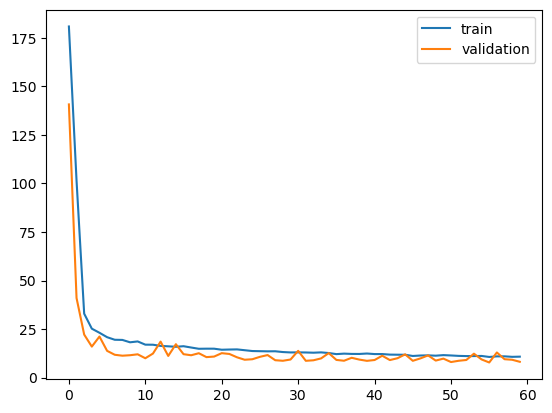

In [38]:
# Plot the chart
plt.plot(axis_x, axis_y, label="train")
plt.plot(axis_val_x, axis_val_y, label="validation")
plt.legend(loc="upper right")
plt.show()  # display

### Load the Best Model

In [59]:
MODEL_FLAG='EfficientNet_V2'

In [60]:
# checkpoint_epoch_41_resnet_pretrainTrue_fusion_20250129-141412.pt
# checkpoint_epoch_53_EfficientNet_V2_pretrainTrue_fusion_20250129-161201.pt
# checkpoint_epoch_55_maxvit_pretrainTrue_fusion_20250130-004044.pt
# checkpoint_epoch_45_SwinTransformer_pretrainTrue_fusion_20250129-151330.pt
# checkpoint_epoch_53_ConvNeXt_pretrainTrue_fusion_20250129-235030.pt

best_model = ckpt_dir + '/checkpoint_epoch_53_EfficientNet_V2_pretrainTrue_fusion_20250129-161201.pt'
best_model

'/mnt/storage/fangyijie/radiomics_ga/ckpt/checkpoint_epoch_53_EfficientNet_V2_pretrainTrue_fusion_20250129-161201.pt'

In [61]:
if MODEL_FLAG == 'resnet':
    from torchvision.models import resnet18, ResNet18_Weights

    if pretrain:
        model = resnet18(weights="IMAGENET1K_V1")
    else:
        model = resnet18(weights=None)

elif MODEL_FLAG == 'SwinTransformer':
    from torchvision.models import swin_v2_t, Swin_V2_T_Weights

    if pretrain:
        model = swin_v2_t(weights="IMAGENET1K_V1")
    else:
        model = swin_v2_t(weights=None)

elif MODEL_FLAG == 'EfficientNet_V2':
    from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

    if pretrain:
        model = efficientnet_v2_s(weights="IMAGENET1K_V1")
    else:
        model = efficientnet_v2_s(weights=None)

elif MODEL_FLAG == 'MobileNet_V3':
    from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

    if pretrain:
        model = mobilenet_v3_small(weights="IMAGENET1K_V1")
    else:
        model = mobilenet_v3_small(weights=None)

elif MODEL_FLAG == 'ViT':
    from torchvision.models import vit_b_16, ViT_B_16_Weights

    if pretrain:
        model = vit_b_16(weights="IMAGENET1K_V1")
    else:
        model = vit_b_16(weights=None)

elif MODEL_FLAG == 'ConvNeXt':
    from torchvision.models import convnext_small, ConvNeXt_Small_Weights

    if pretrain:
        model = convnext_small(weights="IMAGENET1K_V1")
    else:
        model = convnext_small(weights=None)
        
elif MODEL_FLAG == 'maxvit':
    from torchvision.models import maxvit_t, MaxVit_T_Weights

    if pretrain:
        model = maxvit_t(weights="IMAGENET1K_V1")
    else:
        model = maxvit_t(weights=None)

In [62]:
img_model = GaResnetModel(model)
model = FusionModel(img_model, in_channel=351) # 256+95

In [64]:
model.load_state_dict(torch.load(best_model, weights_only=True))
model = model.to(device)

### Test

Following codes are not needed if k-fold validation is enabled.

In [65]:
repeat_test = 5

In [ ]:
test_size = len(test_dataloader)
model.eval()
rmse_list = []

for i in range(repeat_test):
    test_loss = 0
    with torch.no_grad():
        for x1, x2, y in test_dataloader:
            x1, x2, y = x1.to(device), x2.to(device), y.to(device)
            pred = model(x1, x2)
            loss = torch.sqrt(criterion(pred, y)).item()
            # loss = criterion(pred, y).item()
            test_loss += loss
    print(f"Test loss: {test_loss/test_size:>8f}")
    rmse_list.append(test_loss/test_size)

print(f"Average Test RMSE: {np.mean(rmse_list)}")

In [66]:
l1_loss = nn.L1Loss()

In [67]:
test_size = len(test_dataloader)
model.eval()
mae_list = []

for i in range(repeat_test):
    test_loss = 0
    with torch.no_grad():
        for x1, x2, y in test_dataloader:
            x1, x2, y = x1.to(device), x2.to(device), y.to(device)
            pred = model(x1, x2)
            loss = l1_loss(pred, y).item()
            test_loss += loss
    print(f"Test loss: {test_loss/test_size:>8f}")
    mae_list.append(test_loss/test_size)

print(f"Average Test MAE: {np.mean(mae_list)}")
print(f"STD Test MAE: {np.std(mae_list)}")

Test loss: 9.488602
Test loss: 9.547313
Test loss: 9.486832
Test loss: 9.493321
Test loss: 9.496192
Average Test MAE: 9.502451927463214
STD Test MAE: 0.022675557636778584
